# Questão 2 — Aprovação de cartão de crédito (Perceptron)

**Por que Perceptron?** Há rótulo (`Aprovado`, 2 classes), o enunciado diz que existe **uma linha clara** separando bons e maus pagadores e pede o **modelo mais simples possível, com eficiência computacional**. Isso descreve um classificador binário **linear** → Perceptron (aula 10).

## O que mudou em relação ao código da aula 10
O código das classes/funções (`Perceptron`, `plot_comparison`) é **exatamente o da aula**. Só mudei:

1. **Arquivo**: `dataset_credito.csv` (colunas: `Historico_Credito`, `Divida_Atual`, `Aprovado`) → `X = data[:, :2]` e `y = data[:, 2]`, igual à aula.
2. **Rótulos**: o Perceptron usa **−1/+1** (`np.sign`). Na aula os arquivos já vinham com −1/+1 e a linha era `np.where(y == -1, -1, 1)`. Aqui `Aprovado` é **0/1**; se eu usasse a linha da aula, o 0 viraria +1 e **todos** os rótulos seriam +1. Por isso a linha vira `np.where(y == 0, -1, 1)`.
3. **Dados**: usei o dataset inteiro para treinar e avaliar (a prova entrega um único CSV).

In [1]:
# Inclusão das bibliotecas usadas no trabalho
import numpy as np
import matplotlib.pyplot as plt

## Implementação do perceptron (código da aula)

In [2]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=1000, weight_init="random"):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.weights = None
        self.weight_init = weight_init
        self.bias = None
        self.errors_per_epoch = []  # Armazena o erro a cada época

    # Inicializando os pesos de forma customizada

    def _initialize_weights(self, n_features):
        """ Inicializa os pesos de acordo com o método escolhido """
        if self.weight_init == "random":
            self.weights = np.random.rand(n_features)
            self.bias = np.random.rand()
        elif self.weight_init == "zeros":
            self.weights = np.zeros(n_features)
            self.bias = 0
        elif self.weight_init == "normal":
            self.weights = np.random.randn(n_features) * 0.01  # Pequenos valores gaussianos
            self.bias = np.random.randn() * 0.01
        else:
            raise ValueError("Opção inválida para inicialização dos pesos")

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features)  # Inicializa os pesos dinamicamente
        self.bias = 0

        for epoch in range(self.n_epochs):
            errors = 0  # Contador de erros por época

            for i in range(n_samples):
                linear_output = np.dot(X[i], self.weights) + self.bias
                y_pred = np.sign(linear_output)

                # Atualização dos pesos se houver erro
                if y_pred != y[i]:
                    self.weights += self.learning_rate * y[i] * X[i]
                    self.bias += self.learning_rate * y[i]
                    errors += 1  # Incrementa erro se classificação errada

            # Armazena a taxa de erro (erros / total de amostras)
            self.errors_per_epoch.append(errors / n_samples)

            # Parada antecipada se não houver erros
            if errors == 0:
                break

        # Após o treinamento, calcular e exibir estatísticas 
        self._print_training_summary(X, y, epoch + 1)   

            # Método para exibir a acurácia e pesos finais
    def _print_training_summary(self, X, y, epochs):
        y_pred = self.predict(X)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print("\n===== Resumo do Treinamento =====")
        print(f"Acurácia no conjunto de treino: {accuracy:.2f}%")
        print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("=================================\n")


        # Retorna a predição com base no treinamento do Perceptron
    def predict(self, X):
        return np.sign(np.dot(X, self.weights) + self.bias)

    # Faz previsões e, se os rótulos forem fornecidos, exibe métricas
    # Coloque esse método (não está nos slides)
    def predict2(self, X, y, y_true=None):
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)

        # Se y_true for fornecido, calcular métricas de avaliação
        if y_true is not None:
            self.predict_summary(X, y_true, 0, "Teste")

        return y_pred

        # Calculando as métricas da pedrição
    def predict_summary(self, X, y, epochs, phase):
        """ Método para exibir a acurácia, desvio padrão e pesos finais """
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print(f"\n===== Resumo do {phase} =====")
        print(f"Acurácia no conjunto de {phase.lower()}: {accuracy:.2f}%")
        print(f"Desvio Padrão dos Pesos: {std_dev:.5f}")
        if epochs > 0:
            print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("=================================\n")

        # Plota o gráfico da evolução dos erros ao longo das épocas de treinamento.
    def plot_error(self):
        plt.figure(figsize=(8, 4))
        plt.plot(self.errors_per_epoch, marker='o', linestyle='-')
        plt.xlabel("Época")
        plt.ylabel("Taxa de erro")
        plt.title("Evolução do erro ao longo das épocas")
        plt.grid()
        plt.show()

In [3]:
# Gráfico da "fronteira" gerado pelo Perceptron
def plot_decision_boundary(X, y, model, title="Fronteira de Decisão do Perceptron"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar o gráfico
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.show()

In [4]:
# Função para plotar lado a lado: dataset e fronteira de decisão
def plot_comparison(X, y, model):
    # Criar uma grade para o plano cartesiano
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar os subplots (1 linha, 2 colunas)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1 - Fronteira de Decisão
    axes[0].contourf(xx, yy, Z, alpha=0.3)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")
    axes[0].set_title("Fronteira de Decisão do Perceptron")

    # Subplot 2 - Apenas os Dados
    axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")
    axes[1].set_title("Distribuição dos Dados do Dataset")

    plt.tight_layout()
    plt.show()

## Treinamento com o dataset de crédito

Rótulos -1: 150 | Rótulos +1: 150

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 80.00%
Número total de épocas: 100
Pesos finais aprendidos: [-0.25646481 -0.14717797]
Bias final: 0.20000000000000004



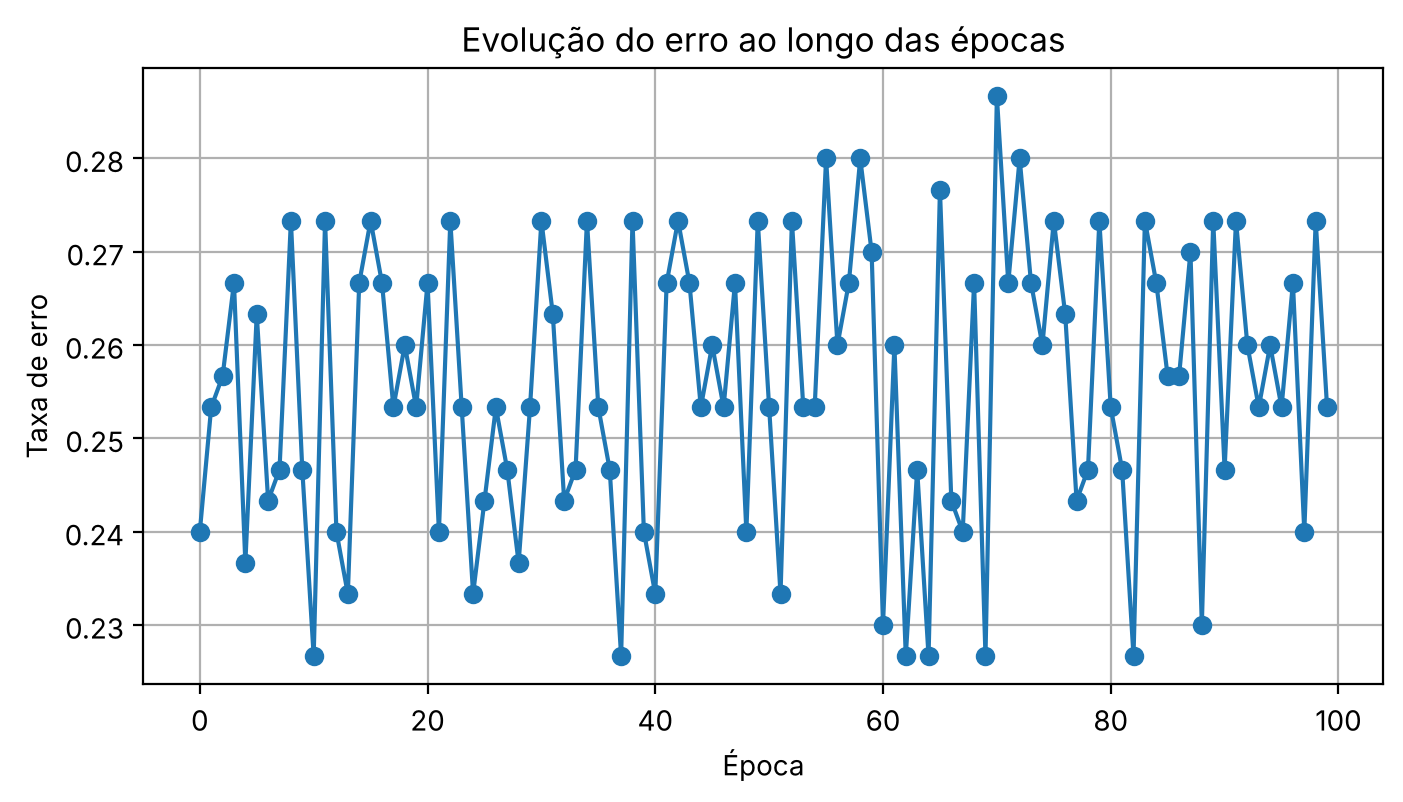

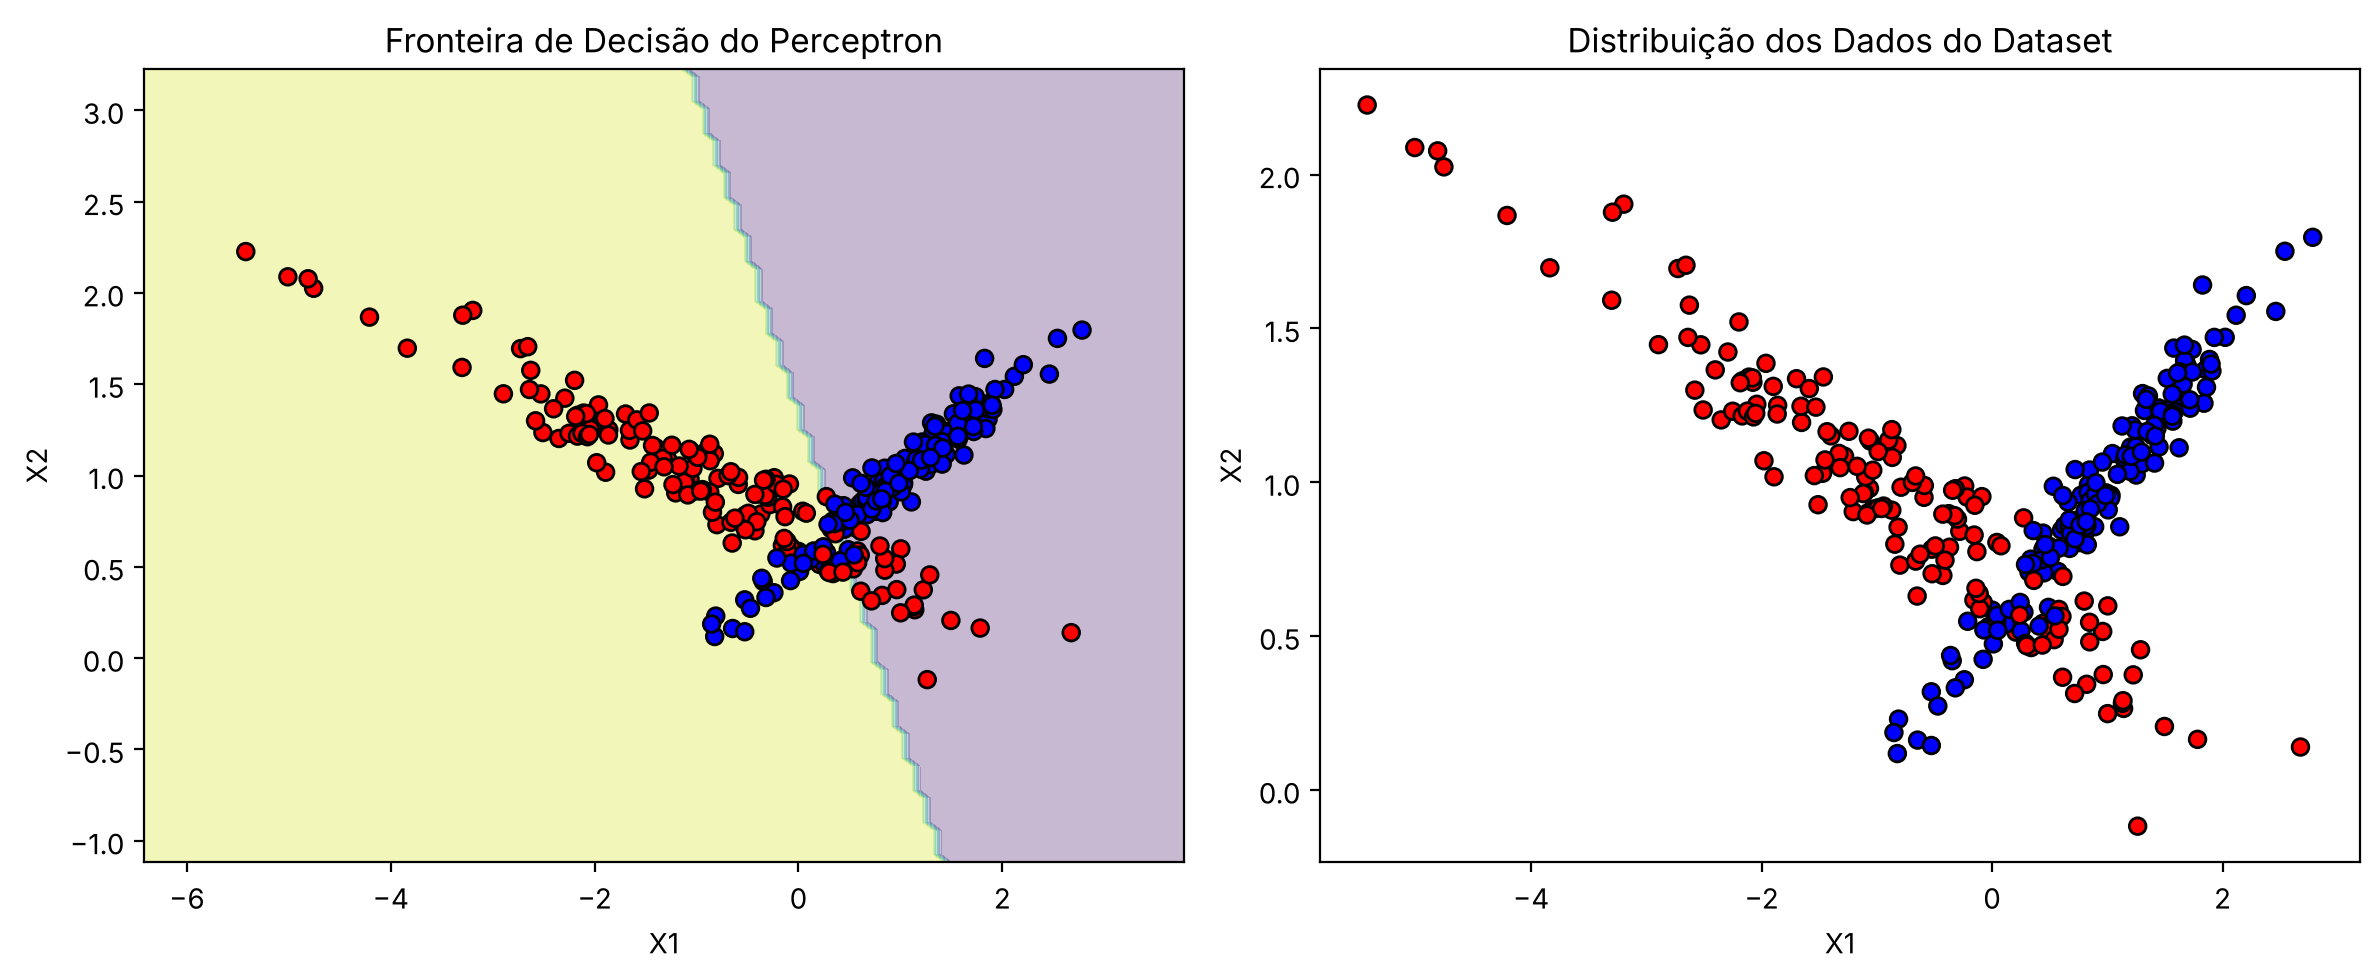

In [5]:
np.random.seed(42)  # para o resultado ser reproduzível

# Importando o dataset da prova
dataset = np.loadtxt("dataset_credito.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X = dataset[:, :2]  # Histórico de Crédito e Dívida Atual
y = dataset[:, 2]   # Aprovado (0 ou 1)

# Converter rótulos de 0/1 para -1/+1 (MUDANÇA em relação à aula: aqui o 0 é a classe negativa)
y = np.where(y == 0, -1, 1)

print("Rótulos -1:", np.sum(y == -1), "| Rótulos +1:", np.sum(y == 1))

# Criação do Perceptron: taxa de aprendizado 0.1 e 100 épocas (mesmos valores da aula)
perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

# Treinamento do Perceptron
perceptron.fit(X, y)

# Fazer previsões
y_pred = perceptron.predict2(X, y)

# Plotar a evolução do erro
perceptron.plot_error()

print("")

# Plot dos gráficos lado a lado
plot_comparison(X, y, perceptron)

## Conclusão

**Algoritmo:** Perceptron, porque o enunciado pede o modelo mais simples e eficiente para um problema binário com suposta separação linear.

**Resultados:** o Perceptron terminou as 100 épocas **sem zerar o erro**: a taxa de erro por época oscila em torno de 0,22 a 0,27 e a acurácia final no conjunto é de **80%**. O gráfico dos dados mostra duas faixas que se **cruzam formando um "X"**: longe do centro uma reta separa bem, mas na região onde as faixas se cruzam as classes se **misturam**, então os dados **não são perfeitamente separáveis por uma reta**, ao contrário do que a análise preliminar do enunciado sugeria.

**Interpretação:** a reta captura a tendência principal (histórico de crédito alto favorece a aprovação), mas cerca de 20% dos clientes ficam do lado errado. Treinar mais épocas não resolve, pois a curva já oscila sem melhorar. Se esse erro não for aceitável para a aprovação de cartões, o próximo passo seria testar um modelo não linear (MLP) e comparar.

**Ressalva:** a acurácia foi medida no mesmo conjunto usado no treino; com divisão treino/teste ela tenderia a ser igual ou um pouco menor.